# Подбор изображений по запросу

---

**Цель**

Разработать демонстрационную версию поиска изображений по запросу.  
Для демонстрационной версии нужно обучить модель, которая получит векторное представление изображения, векторное представление текста, а на выходе выдаст число от 0 до 1 — покажет, насколько текст и картинка подходят друг другу.

---

**Исходные данные**

Набор пар "изображение-описание" с оценками от экспертов и пользователей, набор файлов с изображениями и тексты описаний.

---

**Задачи:**  

- провести исследовательский анализ данных;
- вывести агрегированную оценку на основе экспертных и пользовательских оценок для каждой пары "изображение-описание";
- удалить из обучающего набора изображения, нарушающие требования законодательства (изображения с детьми);
- выполнить векторизацию данных обучающего набора (изображений, текстов, затем объединить их);
- в качестве бейзлайна обучить модель;
- обучить модель на базе нейронной сети (нейросеть);
- проверить модель-нейросеть на тестовых данных;
- сформулировать рекомендации для дальнейшего развития проекта.

In [130]:
#!pip install transformers
#!pip install opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 MB 637.8 kB/s eta 0:00:00m eta 0:00:010:00:03


In [1]:
# Импортируем необходимые библиотеки

import os
import pandas as pd
import numpy as np
import re
import pickle
import tensorflow as tf
import warnings
import time

from pathlib import Path
import pandas as pd
import requests

from tqdm import tqdm
from tqdm import notebook
tqdm.pandas()
from PIL import Image
import cv2

from sklearn.preprocessing import MinMaxScaler, StandardScaler

import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords as nltk_stopwords
from matplotlib import pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
import torchvision.transforms as transforms
from transformers import BertTokenizer, BertModel

import matplotlib.image as mpimg

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing import image
from tensorflow.keras.layers import Dense, Dropout, Flatten, GlobalAveragePooling2D
import sentence_transformers
from sentence_transformers import SentenceTransformer, util
import glob

2023-09-15 12:11:54.641373: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2023-09-15 12:11:55.012233: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2023-09-15 12:11:55.013981: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-09-15 12:11:56.396573: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
RS = 42

In [8]:
#Скачивание файлов в рабочее окружение
!wget -N https://code.s3.yandex.net/datasets/dsplus_integrated_project_4.zip
!unzip -uq dsplus_integrated_project_4.zip
print('-' * 100)
!ls

--2023-09-11 23:29:32--  https://code.s3.yandex.net/datasets/dsplus_integrated_project_4.zip
Распознаётся code.s3.yandex.net (code.s3.yandex.net)… 93.158.134.158, 2a02:6b8::2:158
Подключение к code.s3.yandex.net (code.s3.yandex.net)|93.158.134.158|:443... соединение установлено.
HTTP-запрос отправлен. Ожидание ответа… 304 Not Modified
Файл «dsplus_integrated_project_4.zip» на сервере не изменился. Скачивание пропускается.

----------------------------------------------------------------------------------------------------
 anaconda3			   to_upload
 bin				   tweets_lemm_test.csv
 datasets			   tweets_lemm_train.csv
 dsplus_integrated_project_4.zip   Workroom_CERF.ipynb
 English_level			   Видео
 Image_search			   Документы
 Image_search.ipynb		   Загрузки
 img_embend.pickle		   Изображения
 __MACOSX			   Музыка
 nltk_data			   Общедоступные
"PlayOnLinux's virtual drives"	  'Рабочий стол'
 PortWINE			   ТехТребования
 Prefab_4.ipynb			   Шаблоны
 Studies


In [3]:
#Проверка рабочей области
print (os.getcwd())

/home/wim


In [33]:
PATH_SWITCH = 'local'
#Фиксация пути к файлам
PATH = '/home/wim/to_upload/'
PATH_REMOTE = '/to_upload/'

PATH_IMAGE_TRAIN = PATH + 'train_images/'
PATH_IMAGE_TEST = PATH + 'test_images/'

In [6]:
#Чтение датафреймов
def read_df(path=PATH) -> pd.DataFrame:

    df_train = pd.read_csv(Path(path, 'train_dataset.csv'))
    df_crowd = pd.read_csv(Path(path, 'CrowdAnnotations.tsv'), sep='\t',
                           names=['image', 'query_id', 'share_pos', 'count_pos', 'count_neg'])
    df_expert = pd.read_csv(Path(path, 'ExpertAnnotations.tsv'), sep='\t',
                           names=['image', 'query_id', 'first', 'second', 'third'])
    df_queries = pd.read_csv(Path(path, 'test_queries.csv'), index_col=[0], sep='|')
    df_images = pd.read_csv(Path(path, 'test_images.csv'), sep='|')

    return df_train, df_crowd, df_expert, df_queries, df_images

df_train, df_crowd, df_expert, df_queries, df_images = read_df()

In [7]:
PATH_IMAGE_TEST

'/home/wim/to_uploadtest_images/'

In [8]:
display(df_train.sample(5),
        df_crowd.head(),
        df_expert.head(),
        df_queries.sample(5),
        df_images.sample(5),
        df_train.describe())

,image,query_id,query_text
5379,2844018783_524b08e5aa.jpg,2447284966_d6bbdb4b6e.jpg#2,A young boy in a team sweatshirt is in a sport...
5270,3538213870_9856a76b2a.jpg,2339106348_2df90aa6a9.jpg#2,The girls were in the crowd .
5414,2813992915_f732cf8539.jpg,384577800_fc325af410.jpg#2,A Sheltie dog carries a white-colored toy in i...
2057,1572532018_64c030c974.jpg,3484649669_7bfe62080b.jpg#2,A young girl plays in fountain water .
5136,3484832904_08619300d9.jpg,2384353160_f395e9a54b.jpg#2,An older man in a weathered fedora smiles slig...


,image,query_id,share_pos,count_pos,count_neg
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.0,3,0
1,1056338697_4f7d7ce270.jpg,114051287_dd85625a04.jpg#2,0.0,0,3
2,1056338697_4f7d7ce270.jpg,1427391496_ea512cbe7f.jpg#2,0.0,0,3
3,1056338697_4f7d7ce270.jpg,2073964624_52da3a0fc4.jpg#2,0.0,0,3
4,1056338697_4f7d7ce270.jpg,2083434441_a93bc6306b.jpg#2,0.0,0,3


,image,query_id,first,second,third
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2


,query_id,query_text,image
212,3044359043_627488ddf0.jpg#2,A dog jumping off a dock into a pool of water .,3044359043_627488ddf0.jpg
220,3089107423_81a24eaf18.jpg#0,A camera man is behind his video camera and su...,3089107423_81a24eaf18.jpg
391,3553476195_fb3747d7c1.jpg#1,Two black dogs are playing tug-of-war with an ...,3553476195_fb3747d7c1.jpg
165,2714674623_8cd05ac114.jpg#0,a large man dozes off on the bus .,2714674623_8cd05ac114.jpg
113,2448210587_9fe7ea5f42.jpg#3,A woman and a dog sit on a tree stump .,2448210587_9fe7ea5f42.jpg


,image
90,3386953179_84c2d7922f.jpg
77,973827791_467d83986e.jpg
65,3122579598_14841c038a.jpg
84,2121140070_a09644550b.jpg
94,862177617_c2c0581075.jpg


,image,query_id,query_text
count,5822,5822,5822
unique,1000,977,977
top,3364151356_eecd07a23e.jpg,2600867924_cd502fc911.jpg#2,"Two dogs , one brown and white and one black a..."
freq,10,34,34


Как видно из таблицы, в тренировочном датасете у нас 100 изображений, имеющих 5822 связей с описаниями, 977 из которых уникальны.

In [9]:
#Агрегирующая функция для DF data_expert
def agr_data(row):

    # Если оценки экспертов не равны друг другу, берём среднее
    if row['first'] != row['second'] != row['third']:
        row['agr_expert'] = (row['first'] + row['second'] + row['third']) // 3
    # В любом другом случае медиана
    else:
        row['agr_expert'] = int(np.median(row['first':'third']))

    return row

df_expert = df_expert.progress_apply(agr_data, axis=1)
df_expert

100%|██████████| 5822/5822 [00:04<00:00, 1265.16it/s]


,image,query_id,first,second,third,agr_expert
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1,1
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2,1
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2,1
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2,2
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2,1
...,...,...,...,...,...,...
5817,997722733_0cb5439472.jpg,2981702521_2459f2c1c4.jpg#2,1,1,1,1
5818,997722733_0cb5439472.jpg,2985679744_75a7102aab.jpg#2,1,1,1,1
5819,997722733_0cb5439472.jpg,3150742439_b8a352e1e0.jpg#2,1,1,2,1
5820,997722733_0cb5439472.jpg,3375070563_3c290a7991.jpg#2,1,1,1,1


In [10]:
df_expert.isna().mean()

image         0.0
query_id      0.0
first         0.0
second        0.0
third         0.0
agr_expert    0.0
dtype: float64

In [11]:
df_expert.shape

(5822, 6)

In [12]:
agr_expert_unique = df_expert.agr_expert.unique()
agr_expert_unique

array([1, 2, 3, 4])

Для объединения оценок экспертов и краудсорсинговых оценок используем следующий алгоритм:
1) Если для сочетания изображения и текста отсутствует только одна из двух оценок, выбираем оценку, которая доступна.
2) Если имеются обе оценки, мы обращаем внимание на краудсорсинговую оценку.

Если более половины участников голосования считают, что текст не соответствует изображению, мы уменьшаем оценку на один "экспертный" голос.
Если более половины участников считают, что текст соответствует, мы увеличиваем оценку на один пункт.

Учтите, что один голос эксперта эквивалентен  
1
9
  оценки.

3) Оценка не может быть больше 1 или меньше 0

In [13]:
#Функция аггрегации оценок аутсорса и экспертов
df_merged = df_expert.merge(df_crowd, on = ['image', 'query_id'], how='outer')

def score_aggregate(row) -> object:

    if np.isnan(row['agr_expert']):
        row['score'] = row['share_pos']
    elif np.isnan(row['share_pos']):
        row['score'] = row['agr_expert']
    else:
        row['score'] = row['agr_expert'] * 0.7 + row['share_pos'] * 0.3

    return row

df_merged = df_merged.progress_apply(score_aggregate, axis=1)
df_merged

100%|██████████| 51323/51323 [00:27<00:00, 1846.44it/s]


,image,query_id,first,second,third,agr_expert,share_pos,count_pos,count_neg,score
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1.0,1.0,1.0,1.0,0.000000,0.0,3.0,0.700000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1.0,1.0,2.0,1.0,0.000000,0.0,3.0,0.700000
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1.0,1.0,2.0,1.0,NaN,NaN,NaN,1.000000
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1.0,2.0,2.0,2.0,NaN,NaN,NaN,2.000000
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1.0,1.0,2.0,1.0,NaN,NaN,NaN,1.000000
...,...,...,...,...,...,...,...,...,...,...
51318,997722733_0cb5439472.jpg,543007912_23fc735b99.jpg#2,NaN,NaN,NaN,NaN,0.000000,0.0,3.0,0.000000
51319,997722733_0cb5439472.jpg,544576742_283b65fa0d.jpg#2,NaN,NaN,NaN,NaN,0.333333,1.0,2.0,0.333333
51320,997722733_0cb5439472.jpg,872622575_ba1d3632cc.jpg#2,NaN,NaN,NaN,NaN,1.000000,3.0,0.0,1.000000
51321,997722733_0cb5439472.jpg,888425986_e4b6c12324.jpg#2,NaN,NaN,NaN,NaN,0.000000,0.0,3.0,0.000000


In [14]:
display('Количество пропусков score', df_merged['score'].isna().mean(),
        df_merged['score'].describe())

'Количество пропусков score'

0.0

count    51323.000000
mean         0.212101
std          0.504731
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          4.000000
Name: score, dtype: float64

In [15]:
df_train = pd.merge(df_train, df_merged[['image', 'query_id', 'score']], how='outer', on=['image', 'query_id'])

In [16]:
df_train['query_text'].isna().value_counts()

True     45501
False     5822
Name: query_text, dtype: int64

In [17]:
filling = df_train[df_train['query_text'].notna()]

In [18]:
#Функция заполнения пропусков в описаниях к фото
def fill_text(row) -> object:

    if pd.isnull(row['query_text']):
        texts = filling[filling['query_id'] == row['query_id']]['query_text']
        if len(texts) > 0:
            row['query_text'] = texts.iloc[0]

    return row

df_train = df_train.progress_apply(fill_text, axis=1)

100%|██████████| 51323/51323 [00:35<00:00, 1448.78it/s]


In [19]:
df_train['query_text'].isna().value_counts()

False    50214
True      1109
Name: query_text, dtype: int64

In [20]:
df_train.dropna(inplace=True)

In [21]:
df_train['query_text'].value_counts()

Two white dogs running                                                               176
A white dog is running on gravel away from two people and a black and brown dog .    152
Two children look up .                                                               152
two dogs play together .                                                             144
Two dogs are jumping up at each other .                                              141
                                                                                    ... 
Kid guards face from soccer ball                                                      13
A smaller art festival on the edge of a forest                                        11
a woman enjoying her reading at a coffee shop                                         10
People are inspecting sound equipment indoors .                                       10
Some teenagers are scrambling for a basketball underneath the net .                    9
Name: query_text, Len

In [22]:
df_train['image'].value_counts()

1572532018_64c030c974.jpg    118
3250695024_93e8ab7305.jpg    111
3359551687_68f2f0212a.jpg    102
324208502_674488bcea.jpg     101
2239938351_43c73c887c.jpg    100
                            ... 
3567061016_62768dcce1.jpg     15
363617160_6cb0c723be.jpg      15
3578841731_f775cab089.jpg     14
2295750198_6d152d7ceb.jpg     14
2914206497_5e36ac6324.jpg     10
Name: image, Length: 1000, dtype: int64

In [23]:
mm_scaler = MinMaxScaler()

In [24]:
df_train['score'] = mm_scaler.fit_transform(df_train[['score']])

In [25]:
df_train.sample(10)

,image,query_id,query_text,score
20485,261490838_2f3ac98b12.jpg,3593392955_a4125087f6.jpg#2,Two dogs run down a dirt path in the forest .,0.0625
23416,2815256108_fc1302117d.jpg,3221036999_3f7b152d8a.jpg#2,A skateboarder does a trick on a black and yel...,0.0000
49315,539751252_2bd88c456b.jpg,820169182_f5e78d7d19.jpg#2,Two children look up .,0.0000
43962,3655074079_7df3812bc5.jpg,1262583859_653f1469a9.jpg#2,A man in a bright green shirt riding a bicycle...,0.0000
19871,2594042571_2e4666507e.jpg,917574521_74fab68514.jpg#2,Two girls are dressed the same and one of them...,0.0000
19675,2587818583_4aa8e7b174.jpg,522063319_33827f1627.jpg#2,Two children kneeling down with pirate hats on,0.0000
1951,359837950_9e22ffe6c2.jpg,359837950_9e22ffe6c2.jpg#2,A black dog walking along a rocky terrain .,0.7750
45692,396360611_941e5849a3.jpg,2502905671_c6039804ab.jpg#2,A man playing with his dog on a beach,0.0000
22314,2723477522_d89f5ac62b.jpg,2616643090_4f2d2d1a44.jpg#2,a baby sticking wheat grass into his mouth,0.0000
45330,3741462565_cc35966b7a.jpg,3114944484_28b5bb9842.jpg#2,A group of people with their backs to the came...,0.0000


In [26]:
df_train['score'].describe()

count    50214.000000
mean         0.053998
std          0.127267
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: score, dtype: float64

In [27]:
BLOCK_WORDS = [
    'boy',
    'boys',
    'girl',
    'girls',
    'child',
    'baby',
    'kid',
    'babe',
    'infant',
    'teenager',
    'teenage',
    'teeny',
    'juvenile',
    'teener',
    'young',
    'younger',
    'youngest',
    'youngster',
    'stripling',
    'schoolchild',
    'schoolboy',
    'schoolgirl']

In [18]:
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to /home/wim/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /home/wim/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/wim/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package omw-1.4 to /home/wim/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [28]:
#Функция лематизации текстов
def lemmatize_text(text):
   
    text = re.sub('[^a-zA-Z]', ' ', text).lower()
    text = nltk.word_tokenize(text, language='english')
    text = [nltk.WordNetLemmatizer().lemmatize(word) for word in text]
    return text

In [29]:
def cleaning(row) -> object:

    '''отмечаем тексты для блокирования'''

    text = lemmatize_text(row['query_text'])
    if [i for i in text if i in BLOCK_WORDS]:
        row['to_block'] = 1
    else:
        row['to_block'] = 0

    return row

In [30]:
df_train = df_train.progress_apply(cleaning, axis=1)

100%|██████████| 50214/50214 [00:38<00:00, 1305.75it/s]


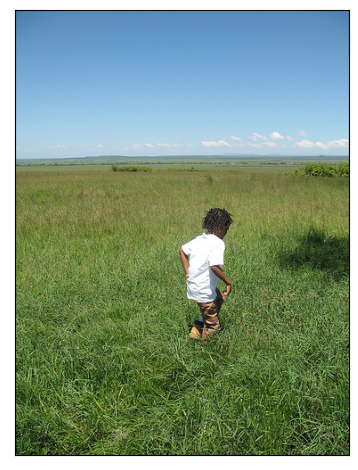

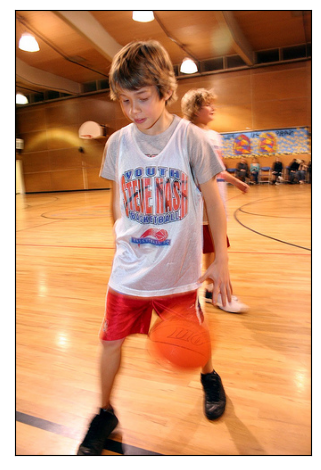

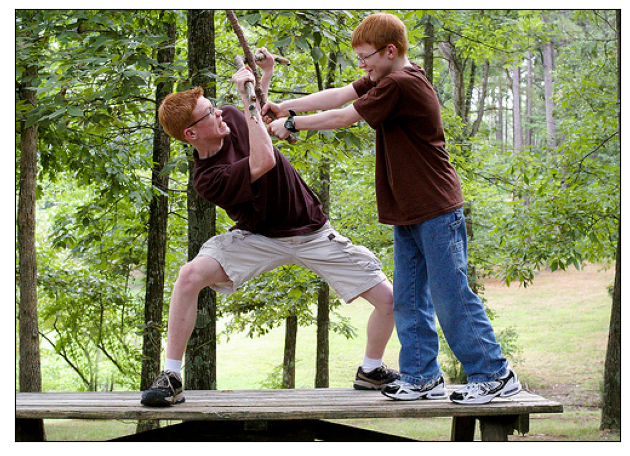

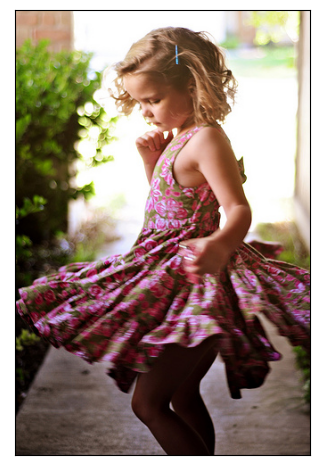

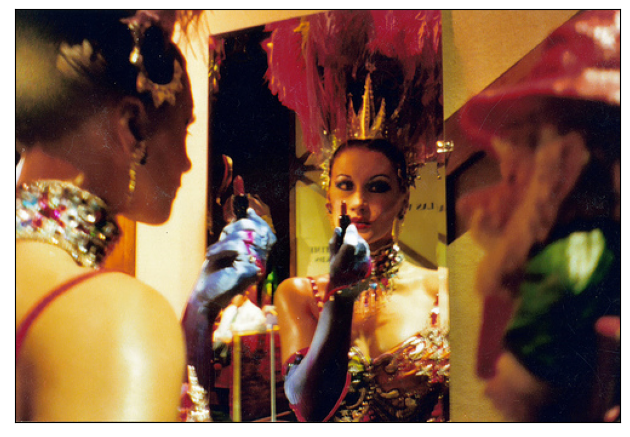

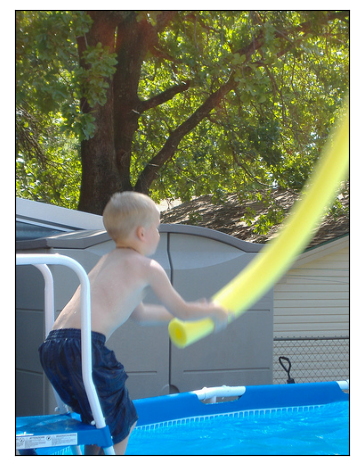

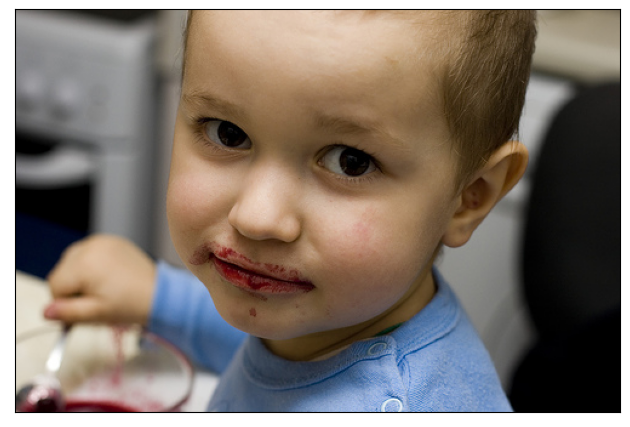

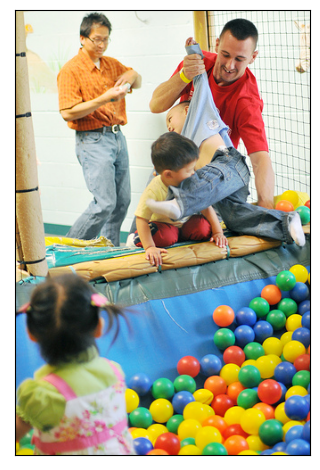

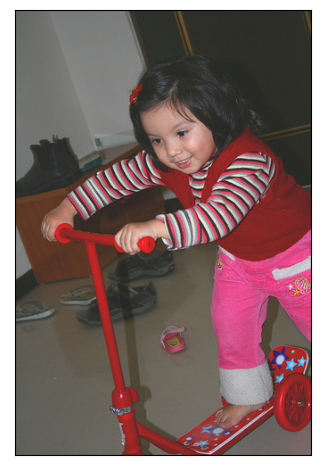

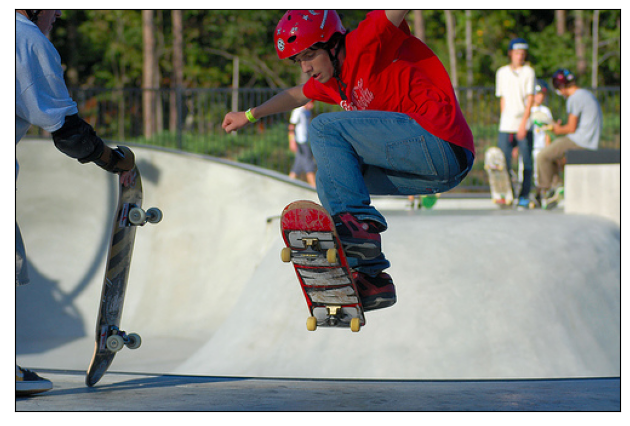

In [34]:
mask = (df_train['query_text']
        .apply(lambda query: any(word in query for word in BLOCK_WORDS)))

pics_to_remove = df_train[mask]['query_id'].apply(lambda x: x[:-2]).unique()

for image_path in np.random.choice(pics_to_remove, 10):
    img = mpimg.imread(os.path.join(PATH_IMAGE_TRAIN, image_path))
    imgplot = plt.imshow(img)
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()
    plt.show()

In [35]:
a = df_train.shape[0]
df_train = df_train[~df_train['image'].isin(pics_to_remove)]
print(f'Удалено {a - df_train.shape[0]} записей')
print('Размер датасета', df_train.shape[0])

Удалено 14233 записей
Размер датасета 35981


# Векторизация изображений

# Необходимо будет изменить качество картинки с 48 на 192

In [36]:
def load_train(path=PATH) -> ImageDataGenerator:

    '''загрузчик данных для обучения'''

    train_datagen = ImageDataGenerator(rescale=1/255.)
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=df_train,
        directory=Path(PATH_IMAGE_TRAIN),
        x_col='image',
        y_col='score',
        target_size=(48, 48),
        batch_size=16,
        class_mode='input',
        seed=RS)

    return train_gen_flow

Проверим выдачу полученного генератора.

Found 35981 validated image filenames.


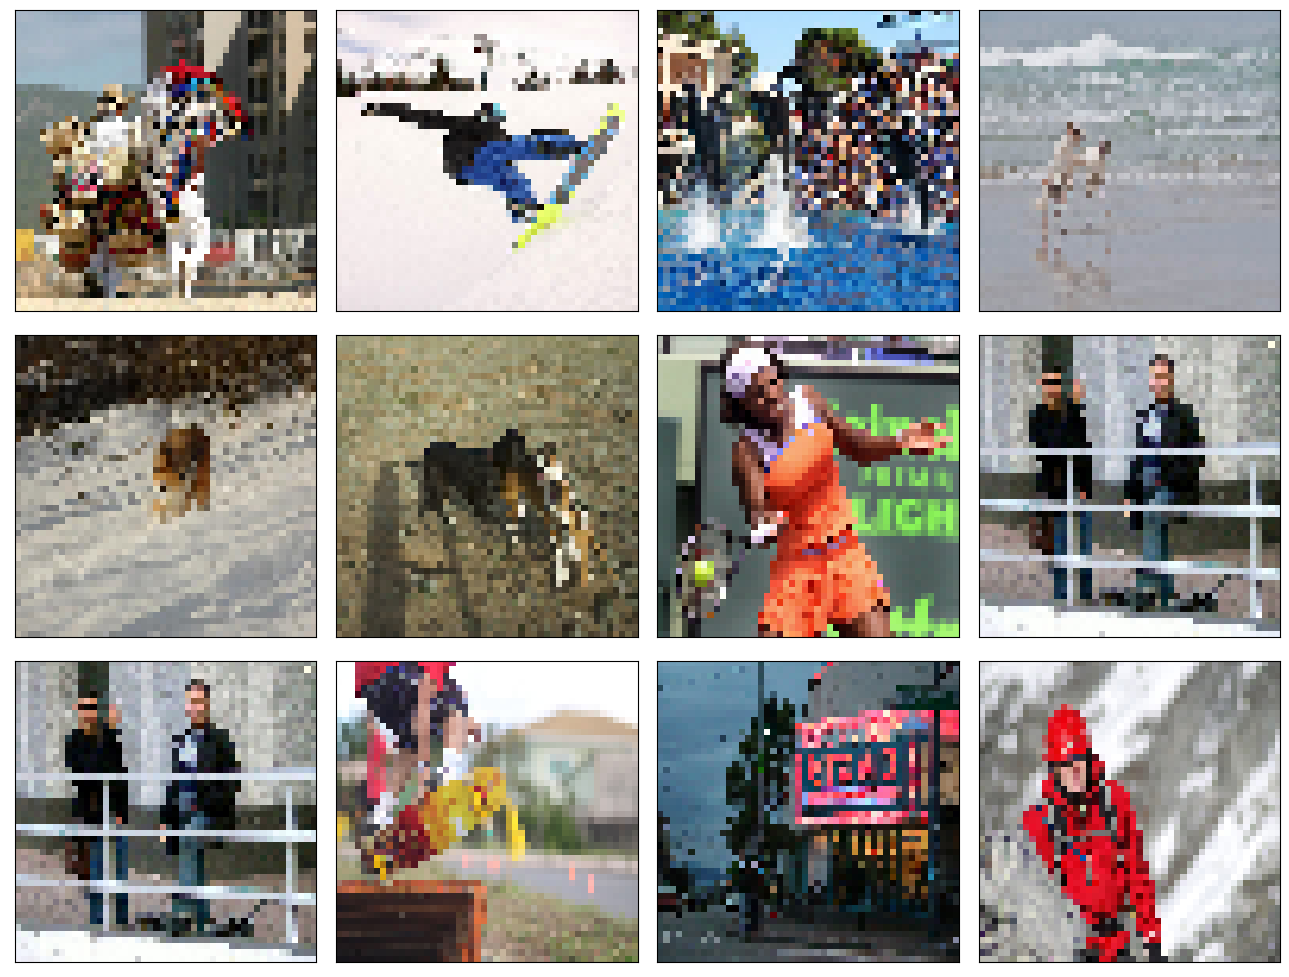

In [37]:
flow_train = load_train()
features, target = next(flow_train)

fig = plt.figure(figsize=(13,10))
for i in range(12):
    fig.add_subplot(3, 4, i+1)
    plt.imshow(features[i])
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()
plt.show()

Все нормально.
В набор не попали фото с детьми

Объявим модель.

In [38]:
# В модель добавил .to(device) необходимо проверить работоспособность, чтобы код успешно работал и на GPU и на CPU
def create_model(input_shape=(48, 48, 3)):

    backbone = ResNet50(input_shape=input_shape,
                        weights='imagenet',
                        include_top=False)
    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    optimizer = Adam(learning_rate=1e-3)
    model.compile(optimizer=optimizer, loss='mean_squared_error',
                  metrics=['mean_absolute_error'])

    return model

In [39]:
#Функция векторизации изображений
def vectorize_pictures(model, df_train):

    predictions = model.predict(df_train)

    return predictions

In [196]:
%%time

img_embend = vectorize_pictures(create_model(), load_train())

Found 35981 validated image filenames.
2249/2249 [==============================] - 331s 147ms/step
CPU times: user 15min 34s, sys: 20.3 s, total: 15min 54s
Wall time: 5min 36s


In [197]:
with open('img_embend.pickle', 'wb') as f:
    pickle.dump(img_embend, f)
None

In [40]:
with open('img_embend.pickle', 'rb') as f:
    img_embend = pickle.load(f)
None

In [41]:
img_embend.shape

(35981, 2048)

In [42]:
img_embend

array([[0.        , 0.        , 0.        , ..., 3.7318666 , 0.        ,
        0.        ],
       [0.        , 0.        , 0.51322436, ..., 3.8616552 , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 4.511449  , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 4.639678  , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 3.9340823 , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 4.185453  , 0.        ,
        0.        ]], dtype=float32)

# Векторизация текстов

In [90]:
import keras_nlp

Using TensorFlow backend


In [91]:
bert = keras_nlp.models.BertBackbone.from_preset('bert_base_en')

433474808/433474808 [==============================] - 203s 0us/step


In [85]:
preprocessor = keras_nlp.models.BertPreprocessor.from_preset('bert_base_en')

In [86]:
def vectorize_text(model, data, preprocessor=preprocessor, batch_size=32, bar=True, verbose=0) -> np.array:
    
    '''преобразуем тексты в словарь токенов, масок и паддингов'''

    embeddings = []
    tokenized = preprocessor(data)

    if bar:
        for i in notebook.tqdm(range(tokenized['token_ids'].shape[0] // batch_size + 1)):
        
            tokens = tokenized['token_ids'][batch_size*i:batch_size*(i+1)]
            token_types = tokenized['segment_ids'][batch_size*i:batch_size*(i+1)]
            mask = tokenized['padding_mask'][batch_size*i:batch_size*(i+1)]
            
            batch = {'token_ids' : tokens,
                    'segment_ids' : token_types, 
                    'padding_mask' : mask}
                    
            batch_embeddings = model.predict(batch, verbose=verbose)
            
            embeddings.append(batch_embeddings['pooled_output'])

    else:
        for i in range(tokenized['token_ids'].shape[0] // batch_size + 1):
        
            tokens = tokenized['token_ids'][batch_size*i:batch_size*(i+1)]
            token_types = tokenized['segment_ids'][batch_size*i:batch_size*(i+1)]
            mask = tokenized['padding_mask'][batch_size*i:batch_size*(i+1)]
            
            batch = {'token_ids' : tokens,
                    'segment_ids' : token_types, 
                    'padding_mask' : mask}
                    
            batch_embeddings = model.predict(batch, verbose=verbose)
            
            embeddings.append(batch_embeddings['pooled_output'])

    return np.concatenate(embeddings)

In [45]:
text = list(df_train['query_text'])

In [144]:
text_embeds = vectorize_text(model=bert, data=text)

KeyboardInterrupt: 

In [30]:
with open('train_text_embend.pickle', 'wb') as f:
    pickle.dump(train_text_embend, f)
None

In [46]:
with open('train_text_embend.pickle', 'rb') as f:
    train_text_embend = pickle.load(f)
None

In [47]:
train_text_embend.head()

,0,1,2,3,4,5,6,7,8,9,...,758,759,760,761,762,763,764,765,766,767
0,-0.987833,0.673303,2.721748,1.265375,1.239629,1.36147,-0.254034,-0.182506,0.504412,-0.342732,...,1.039769,-0.857855,1.568307,-0.107012,0.545149,-2.523912,0.758081,0.097727,-0.134123,0.722528
1,-0.987833,0.673303,2.721748,1.265375,1.239629,1.36147,-0.254034,-0.182506,0.504412,-0.342732,...,1.039769,-0.857855,1.568307,-0.107012,0.545149,-2.523912,0.758081,0.097727,-0.134123,0.722528
2,-0.987833,0.673303,2.721748,1.265375,1.239629,1.36147,-0.254034,-0.182506,0.504412,-0.342732,...,1.039769,-0.857855,1.568307,-0.107012,0.545149,-2.523912,0.758081,0.097727,-0.134123,0.722528
3,-0.987833,0.673303,2.721748,1.265375,1.239629,1.36147,-0.254034,-0.182506,0.504412,-0.342732,...,1.039769,-0.857855,1.568307,-0.107012,0.545149,-2.523912,0.758081,0.097727,-0.134123,0.722528
4,-0.987833,0.673303,2.721748,1.265375,1.239629,1.36147,-0.254034,-0.182506,0.504412,-0.342732,...,1.039769,-0.857855,1.568307,-0.107012,0.545149,-2.523912,0.758081,0.097727,-0.134123,0.722528


In [48]:
features = np.concatenate((img_embend, train_text_embend), axis=1)
features.shape

(35981, 2816)

In [49]:
target = np.array(df_train['score'])
target.shape

(35981,)

In [50]:
groups = df_train.image.values

In [51]:
groups.shape

(35981,)

In [52]:
spliter = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=RS)
train_id, test_id = next(spliter.split(X=features, y=target, groups=groups))

features_train, features_test = features[train_id], features[test_id]
target_train, target_test = target[train_id], target[test_id]

print(features_train.shape, features_test.shape, target_train.shape, target_test.shape)

(25061, 2816) (10920, 2816) (25061,) (10920,)


In [53]:
#baseline model

model_r = Ridge().fit(features_train, target_train)
predictions = model_r.predict(features_test)
np.sqrt(np.sqrt(mean_squared_error(target_test, predictions)))

14.850355937286896

# Построение базовой нейронной сети

In [59]:
# Переведём выборки в тензоры
X_train = torch.FloatTensor(np.array(features_train))
X_test = torch.FloatTensor(np.array(features_test))
y_train = torch.FloatTensor(np.array(target_train))
y_test = torch.FloatTensor(np.array(target_test))

Проблемка со скэйлером, надо решить этот вопрос, вполне вероятно его позже делать необходимо

In [55]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [56]:
# Создадим ПНС
class Net(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons):
            super(Net, self).__init__()
            
            self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
            self.act1 = nn.ReLU()
            self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
            self.act2 = nn.ReLU()
            self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)
            
    def forward(self, x):
        x = self.fc1(x)
        x = self.act1(x)
        x = self.fc2(x)
        x = self.act2(x)
        x = self.fc3(x)
        
        return x

In [57]:
n_in_neurons = X_train.shape[1]
n_hidden_neurons_1 = 15
n_hidden_neurons_2 = 10
n_out_neurons = 1

net = Net(n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons)
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
loss = nn.MSELoss()

In [60]:
dataset_train = torch.utils.data.TensorDataset(X_train, y_train)
dataset_test = torch.utils.data.TensorDataset(X_test, y_test)

train_dataloader = DataLoader(dataset_train, batch_size=30, shuffle=True,
                              num_workers=0)
test_dataloader = DataLoader(dataset_test, batch_size=30, num_workers=0) 

In [61]:
class CustomEarlyStopping():
    """
    Ранняя остановка, чтобы остановить тренировку, когда потеря не улучшается после определенной эпохи.
    """
    def __init__(self, patience=5, min_delta=0):
        """
        :param patience: сколько эпох ждать, прежде чем остановиться, когда потеря не улучшается
        :param min_delta: минимальная разница между loss/метриками, если улучшений нет, то остановим обучение
        """
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss == None:
            self.best_loss = val_loss
        elif self.best_loss - val_loss > self.min_delta:
            self.best_loss = val_loss
            # reset counter if validation loss improves
            self.counter = 0
        elif self.best_loss - val_loss < self.min_delta:
            self.counter += 1
            print(f"INFO: Early stopping counter {self.counter} of {self.patience}")
            if self.counter >= self.patience:
                print('INFO: Early stopping')
                self.early_stop = True

In [63]:
# Обучим нейросеть
early_stopping = CustomEarlyStopping(patience=4, min_delta=20)

num_epochs = 1
for epoch in range(num_epochs):
    net.train()
    for batch in train_dataloader:
        data_train, target_train = batch #выгружаем данные 
        optimizer.zero_grad()

        preds = net.forward(data_train).flatten()

        loss_value = torch.sqrt(loss(preds, target_train))
        loss_value.backward()
        optimizer.step()
    
    if epoch % 200 == 0:
        predicted_temp = [] 
        with torch.no_grad():
            net.eval()
            for batch in test_dataloader:
                data_test, target_test = batch #выгружаем данные

                test_preds = net.forward(data_test).flatten()
                predicted_temp.append(test_preds)
                RMSE_loss = torch.sqrt(loss(test_preds, target_test))

        predicted_temp = torch.cat(predicted_temp).detach().numpy()
        RMSE = mean_squared_error(y_test, predicted_temp, squared=False)
        early_stopping(RMSE)
        if early_stopping.counter == 0:
            best_rmse = RMSE
            best_predicted_temp = predicted_temp
        print(f"epoch:{epoch}, RMSE test: {RMSE}")

        if early_stopping.early_stop:
            print('Early Stopping!!!')
            print(f'Best RMSE test {best_rmse}')
            break 

epoch:0, RMSE test: 0.1323716789484024


# Тестирование нейронной сети

In [64]:
img_names = list(glob.glob(str(Path(PATH, 'test_images', '*.jpg'))))
img_emb = model.encode([Image.open(filepath) for filepath in img_names], batch_size=16, convert_to_tensor=True, show_progress_bar=True)

NameError: name 'model' is not defined

In [66]:
def load_test(path=PATH) -> ImageDataGenerator:
    test_datagen = ImageDataGenerator(rescale=1/255.)
    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=df_images,
        directory=Path(PATH_IMAGE_TEST),
        x_col='image',
        y_col=None,
        target_size=(256, 256),
        batch_size=64,
        class_mode='input',
        seed=RS)

    return test_gen_flow

In [67]:
pict_embeds_test = vectorize_pictures(create_model(), load_test())
pict_embeds_test.shape

2023-09-15 12:22:54.639930: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2023-09-15 12:22:54.640835: W tensorflow/core/common_runtime/gpu/gpu_device.cc:1960] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Found 100 validated image filenames.


2023-09-15 12:22:59.549531: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 268435456 exceeds 10% of free system memory.
2023-09-15 12:22:59.947530: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 268435456 exceeds 10% of free system memory.
2023-09-15 12:23:00.128174: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 276889600 exceeds 10% of free system memory.
2023-09-15 12:23:00.275605: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 268435456 exceeds 10% of free system memory.
2023-09-15 12:23:00.460720: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 268435456 exceeds 10% of free system memory.


2/2 [==============================] - 15s 4s/step


(100, 2048)

In [87]:
def get_picture(text) -> None:

    '''Проверяем легальность запроса, получаем наиболее похожие картинки,
    если описание среди оригинальных картинок - добавляем последней верную'''
    
     
    if [i for i in lemmatize_text(text) if i in BLOCK_WORDS]: #проверяем не нужно ли вывести на экран заглушку
        print('')
        print('-' * 20, text, '-' * 20)
        print('')
        print('This image is unavailable in your country in compliance with local laws.')
        print('')
    else:
        text_embed = vectorize_text_with_bert(model=model_name, data=[text], bar=False) #получаем эмбеддинг текста
        X = np.concatenate(( #объединяем вектора тестовых картинок с эмбеддингом текста
            pict_embeds_test,
            np.resize(text_embed, (pict_embeds_test.shape[0],768))),
            axis=1)
        X = scaler.transform(X)
        predictions = net.forward(X) #получаем предсказания оценок экспертов
        predictions = predictions.argmax()
        df = pd.concat((df_images, pd.Series(np.reshape(predictions, (predictions.shape[0],)), name='pred')), axis=1) #добавляем оценки к номерам картинок
        top = list(df.sort_values(by='pred', ascending=False)['image'].head(5)) #получили топ 5 имён файлов с картинками
        top_score = list(df.sort_values(by='pred', ascending=False)['pred'].head(5)) #получили топ 5 оценок
        
        print('')
        print('-' * 20, text, '-' * 20)
        print('')
        
        fig = plt.figure(figsize=(15,5)) #выводим на экран 5 наиболее похожих картинок
        plt.rcParams['axes.edgecolor'] = 'black'
        plt.rcParams['axes.linewidth'] = 0
        for i in range(5):
            fig.add_subplot(1, 6, i+1, title=round(top_score[i], 2))
            image = Image.open(img_names[hits[i]['corpus_id']])
            plt.imshow(image)
            plt.xticks([])
            plt.yticks([])
            plt.tight_layout()
        
        if text in list(df_queries['query_text']): #если текст был в исходном файле с описаниями - добавляем оригинальную картинку
            plt.rcParams['axes.edgecolor'] = 'green'
            plt.rcParams['axes.linewidth'] = 5
            fig.add_subplot(1, 6, 6)
            image = Image.open(Path(PATH, 'test_images', df_queries.iloc[df_queries[df_queries['query_text'] == query].index[0]]['image']))
            plt.imshow(image)
            plt.xticks([])
            plt.yticks([])
            plt.tight_layout()
        
        plt.show()

    return None

In [76]:
samples = df_queries.sample(5)
text_test = list(samples['query_text'])
text_test

['A blonde girl in a black cape stands with other children in costumes .',
 'A little girl leans over the side of a wall to feed ducks in the water .',
 'Young children play in the sprinkler .',
 'Two white dogs chase after a red ball in a yard in front of a white fence .',
 'People are watching a skier perform a trick in the air .']

In [88]:

for text in text_test:
    get_picture(text)


-------------------- A blonde girl in a black cape stands with other children in costumes . --------------------

This image is unavailable in your country in compliance with local laws.


-------------------- A little girl leans over the side of a wall to feed ducks in the water . --------------------

This image is unavailable in your country in compliance with local laws.


-------------------- Young children play in the sprinkler . --------------------

This image is unavailable in your country in compliance with local laws.



TypeError: vectorize_text_with_bert() got an unexpected keyword argument 'model'

# Тестирование нейронной сети CLIP

In [87]:
model = SentenceTransformer('clip-ViT-B-32')

In [79]:
def search(query) -> None:

    '''Проверяем легальность запроса, получаем наиболее похожие картинки,
    если описание среди оригинальных картинок - добавляем последней верную'''
    
    if [i for i in lemmatize_text(query) if i in BLOCK_WORDS]: #проверяем не нужно ли вывести на экран заглушку
        print('')
        print('-' * 20, query, '-' * 20)
        print('')
        print('This image is unavailable in your country in compliance with local laws.')
        print('')
    else:
        query_emb = model.encode([query], convert_to_tensor=True, show_progress_bar=False) #получаем эмбеддинг запроса
        # Используем функцию util.semantic_search, которая вычисляет косинусную схожесть
        # между эмбеддингом запроса и всеми картинками из базы.
        # Далее функция возвращает top_k картинок с наивысшим рейтингом
        hits = util.semantic_search(query_emb, img_emb, top_k=5)[0]
        print('')
        print('-' * 20, query, '-' * 20)
        print('')

        fig = plt.figure(figsize=(15,5)) #выводим на экран 5 наиболее похожих картинок
        plt.rcParams['axes.edgecolor'] = 'black'
        plt.rcParams['axes.linewidth'] = 0
        for i in range(5):
            fig.add_subplot(1, 6, i+1, title=round(hits[i]['score'], 2))
            image = Image.open(img_names[hits[i]['corpus_id']])
            plt.imshow(image)
            plt.xticks([])
            plt.yticks([])
            plt.tight_layout()
        
        if query in list(df_queries['query_text']): #если текст был в исходном файле с описаниями - добавляем оригинальную картинку
            plt.rcParams['axes.edgecolor'] = 'green'
            plt.rcParams['axes.linewidth'] = 5
            fig.add_subplot(1, 6, 6)
            image = Image.open(Path(PATH, 'test_images', df_queries.iloc[df_queries[df_queries['query_text'] == query].index[0]]['image']))
            plt.imshow(image)
            plt.xticks([])
            plt.yticks([])
            plt.tight_layout()
        
        plt.show()

    return None

In [80]:
samples = df_queries.sample(5)
queries = list(samples['query_text'])
queries

['Three women are looking into a camera .',
 'A group of children dressed for halloween stand in line with the exception of one girl .',
 'Children in costumes standing in line .',
 'One person snowboarding while others look on .',
 'Young children play in the sprinkler .']

In [71]:
for query in queries:
    search(query)

NameError: name 'search' is not defined